# Preparación del entorno

In [ ]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import warnings
warnings.simplefilter(action='ignore', category=FutureWarning)

In [ ]:
from pathlib import Path

# Buscar datasets/ desde la raíz del proyecto o desde notebooks/.
project_root = next(
    (folder for folder in (Path.cwd(), *Path.cwd().parents)
     if (folder / "datasets").is_dir()),
    None,
)
if project_root is None:
    raise FileNotFoundError(
        "No se encontró datasets/. Abrí el notebook dentro del proyecto "
        "y conservá la carpeta datasets/ junto a notebooks/."
    )
dataset_dir = project_root / "datasets" / "ej1"
print("Datos locales:", dataset_dir)


In [ ]:
# Cargamos todos los archivos
ds_themes=pd.read_csv(dataset_dir / 'themes.csv')
ds_themes_trabajo=ds_themes.copy()

ds_sets=pd.read_csv(dataset_dir / 'sets.csv')
ds_sets_trabajo=ds_sets.copy()

ds_parts=pd.read_csv(dataset_dir / 'parts.csv')
ds_parts_trabajo=ds_parts.copy()

ds_part_relationships=pd.read_csv(dataset_dir / 'part_relationships.csv')
ds_part_relationships_trabajo=ds_part_relationships.copy()

ds_part_categories=pd.read_csv(dataset_dir / 'part_categories.csv')
ds_part_categories_trabajo=ds_part_categories.copy()

ds_minifigs=pd.read_csv(dataset_dir / 'minifigs.csv')
ds_minifigs_trabajo=ds_minifigs.copy()

ds_inventory_sets=pd.read_csv(dataset_dir / 'inventory_sets.csv')
ds_inventory_sets_trabajo=ds_inventory_sets.copy()

ds_inventory_parts=pd.read_csv(dataset_dir / 'inventory_parts.csv.gz')
ds_inventory_parts_trabajo=ds_inventory_parts.copy()

ds_inventory_minifigs=pd.read_csv(dataset_dir / 'inventory_minifigs.csv')
ds_inventory_minifigs_trabajo=ds_inventory_minifigs.copy()

ds_inventories=pd.read_csv(dataset_dir / 'inventories.csv')
ds_inventories_trabajo=ds_inventories.copy()

ds_elements=pd.read_csv(dataset_dir / 'elements.csv')
ds_elements_trabajo=ds_elements.copy()

ds_colors=pd.read_csv(dataset_dir / 'colors.csv')
ds_colors_trabajo=ds_colors.copy()

# Ejercicio 1 - Pregunta 1
## ¿Los sets que incluyen otros sets tienden a tener más piezas que aquellos que no incluyen sub-sets?

Según los criterios de Rebrickable, un sub-set es un modelo individual, completo e independiente que forma parte de un set con múltiples modelos. Se excluyen construcciones incompletas, pequeños ensamblajes, el modelo principal del set y aquellos modelos que presentan poca utilidad o interés para otros usuarios.

fuente: https://rebrickable.com/help/sets-types/

## Identificación de subsets
Unimos inventory_sets con inventories para relacionar cada sub-set con el set principal al que pertenece.


In [ ]:
# Seleccionamos la última versión del inventario de cada set
inventarios_ultima_version = (
    ds_inventories_trabajo
    .sort_values('version')
    .drop_duplicates('set_num', keep='last')
)

# Nos quedamos con los sub-sets correspondientes a la última versión
ds_subsets = ds_inventory_sets_trabajo.merge(
    inventarios_ultima_version[['id', 'set_num', 'version']],
    left_on='inventory_id',
    right_on='id',
    suffixes=('_sub_set', '_set_principal')
)

sets_con_subsets = ds_subsets['set_num_set_principal'].unique()

ds_sets_trabajo['tiene_subsets'] = (
    ds_sets_trabajo['set_num'].isin(sets_con_subsets)
)

## Decisión sobre versiones
Para evitar que un mismo set tenga un peso excesivo en el análisis debido a la existencia de múltiples versiones de su inventario, se decidió utilizar únicamente la última versión disponible de cada set. De lo contrario, un set con muchas versiones podría aparecer repetidamente y afectar los resultados. Por ejemplo, si un set tuviera muchas versiones con pocas piezas, podría tener una influencia desproporcionada sobre las medidas obtenidas y sesgar la comparación entre sets con y sin sub-sets.

También se consideró la posibilidad de promediar la información entre las distintas versiones de un mismo set. Sin embargo, esta alternativa fue descartada porque las versiones representan revisiones sucesivas de un mismo inventario y no observaciones independientes. Promediarlas implicaría combinar información potencialmente desactualizada con versiones más recientes, generando un valor que no necesariamente representa ninguna versión real del set. Por este motivo, se optó por utilizar únicamente la versión más reciente, asumiendo que es la que contiene la información más actualizada disponible.

## Cálculo de la cantidad total de piezas

El campo num_parts de sets.csv no considera los sub-sets como piezas. Por eso, para los sets que contienen sub-sets, sumamos también las piezas correspondientes a esos modelos.

In [ ]:
# Relacionamos cada sub-set con su cantidad de piezas
ds_subsets_piezas = ds_subsets.merge(
    ds_sets_trabajo[['set_num', 'num_parts']],
    left_on='set_num_sub_set',
    right_on='set_num',
    how='left'
)

# Cantidad real de piezas aportadas por cada sub-set
ds_subsets_piezas['num_parts_aportadas'] = (
    ds_subsets_piezas['num_parts'] * ds_subsets_piezas['quantity']
)

# Piezas aportadas por todos los sub-sets de cada set principal
piezas_subsets = (
    ds_subsets_piezas
    .groupby('set_num_set_principal')['num_parts_aportadas']
    .sum()
)

# Asignación directa, sin merge
ds_sets_trabajo['num_parts_subsets'] = (
    ds_sets_trabajo['set_num'].map(piezas_subsets).fillna(0)
)

ds_sets_trabajo['num_parts_total'] = (
    ds_sets_trabajo['num_parts'] + ds_sets_trabajo['num_parts_subsets']
)

Esto genera las siguientes variables derivadas:

- tiene_subsets: indica si el set contiene al menos un sub-set.
- num_parts_subsets: cantidad de piezas aportadas por los sub-sets.
- num_parts_total: cantidad total de piezas del set, considerando también las piezas correspondientes a sus sub-sets.

### Datos faltantes

No se encontraron valores nulos en las variables utilizadas para el análisis.

Además, existen sets sin contenido documentado en los inventarios. Como no es posible determinar su cantidad real de piezas, se excluyeron del análisis mediante:

In [ ]:
ds_sets_con_piezas = ds_sets_trabajo[
    ds_sets_trabajo['num_parts_total'] > 0
]

No se imputaron valores, ya que no se trata de un dato faltante que pueda estimarse razonablemente.

In [ ]:
ds_sets_con_piezas['num_parts_total'].describe()

,num_parts_total
count,21177.000000
mean,255.702319
std,570.952537
min,1.000000
25%,20.000000
50%,66.000000
75%,254.000000
max,17040.000000


### Valores atípicos

Se utilizó el criterio del rango intercuartílico (IQR) para identificar valores atípicos en num_parts_total.

Se encontraron 2.359 valores atípicos, todos correspondientes al extremo superior de la distribución.

Estos valores no fueron eliminados, ya que corresponden a sets reales con una cantidad elevada de piezas. Debido a la fuerte asimetría de la variable, se utilizó una escala logarítmica en las visualizaciones.

In [ ]:
Q1 = ds_sets_con_piezas['num_parts_total'].quantile(0.25)
Q3 = ds_sets_con_piezas['num_parts_total'].quantile(0.75)

IQR = Q3 - Q1

limite_inferior = Q1 - 1.5 * IQR
limite_superior = Q3 + 1.5 * IQR

atipicos = ds_sets_con_piezas[
    (ds_sets_con_piezas['num_parts_total'] < limite_inferior) |
    (ds_sets_con_piezas['num_parts_total'] > limite_superior)
]

len(atipicos)

2359

### Exploración y relación entre variables

Se analizaron las variables:

- Cualitativa: tiene_subsets, (True/False).
- Cuantitativa: num_parts_total, que representa la cantidad total de piezas del set, incluyendo las piezas de sus sub-sets.

Para comparar ambos grupos se utilizó un boxplot, que permite observar la distribución, mediana, dispersión y valores atípicos.

In [ ]:
a = ds_sets_con_piezas.loc[
    ~ds_sets_con_piezas['tiene_subsets'],
    'num_parts_total'
]

b = ds_sets_con_piezas.loc[
    ds_sets_con_piezas['tiene_subsets'],
    'num_parts_total'
]

plt.figure(figsize=(8, 5))

plt.boxplot(
    [a, b],
    tick_labels=['Sin sub-sets', 'Con sub-sets']
)

plt.yscale('log')

plt.title('Cantidad total de piezas según presencia de sub-sets')
plt.ylabel('Cantidad total de piezas')

plt.show()

Se identificaron valores atípicos en la cantidad total de piezas mediante el criterio del rango intercuartílico. Estos valores no fueron eliminados, ya que representan sets reales con una cantidad elevada de piezas y no necesariamente errores en los datos. Por lo tanto, se mantienen para evitar perder información relevante del dominio.

Además, se calcularon la media y la mediana de cada grupo:

In [ ]:
resultado = (
    ds_sets_con_piezas
    .groupby('tiene_subsets')['num_parts_total']
    .agg(['count', 'mean', 'median'])
    .rename(index={
        False: 'Sin sub-sets',
        True: 'Con sub-sets'
    })
)

resultado

               count        mean  median
tiene_subsets                           
Sin sub-sets   19909  233.499071    60.0
Con sub-sets    1268  604.317823   256.0

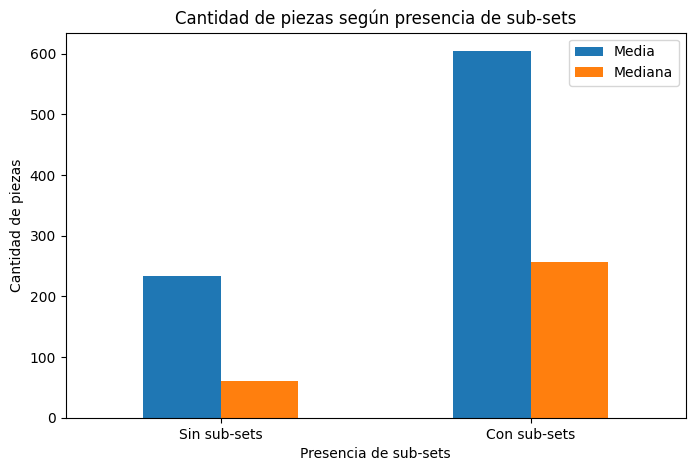

In [ ]:
# Comparación de cantidad de piezas según presencia de sub-sets

comparacion = (
    ds_sets_con_piezas
    .groupby('tiene_subsets')['num_parts_total']
    .agg(['mean', 'median'])
    .rename(index={
        False: 'Sin sub-sets',
        True: 'Con sub-sets'
    })
)

ax = comparacion.plot(
    kind='bar',
    figsize=(8, 5)
)

plt.title('Cantidad de piezas según presencia de sub-sets')
plt.xlabel('Presencia de sub-sets')
plt.ylabel('Cantidad de piezas')
plt.xticks(rotation=0)
plt.legend(['Media', 'Mediana'])

plt.show()

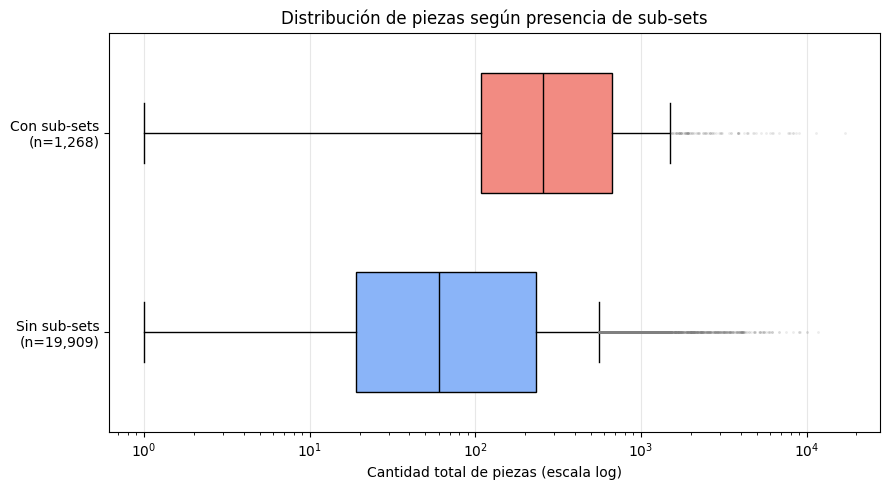

In [ ]:
a = ds_sets_con_piezas.loc[
    ~ds_sets_con_piezas['tiene_subsets'],
    'num_parts_total'
]

b = ds_sets_con_piezas.loc[
    ds_sets_con_piezas['tiene_subsets'],
    'num_parts_total'
]

plt.figure(figsize=(9, 5))

bp = plt.boxplot(
    [a, b],
    vert=False,
    widths=0.6,
    patch_artist=True,
    flierprops=dict(
        marker='o',
        ms=2,
        alpha=0.15,
        mfc='gray',
        mec='none'
    )
)

for p, c in zip(bp['boxes'], ['#8ab4f8', '#f28b82']):
    p.set_facecolor(c)

for m in bp['medians']:
    m.set_color('black')

plt.xscale('log')

plt.yticks(
    [1, 2],
    [f'Sin sub-sets\n(n={len(a):,})',
     f'Con sub-sets\n(n={len(b):,})']
)

plt.xlabel('Cantidad total de piezas (escala log)')
plt.title('Distribución de piezas según presencia de sub-sets')
plt.grid(axis='x', alpha=0.3)

plt.tight_layout()
plt.show()

Se comparan ambos grupos mediante un diagrama de caja, utilizando una escala logarítmica en el eje horizontal debido a la fuerte asimetría de la cantidad de piezas y a la presencia de valores que abarcan varios órdenes de magnitud.

La línea central representa la mediana, la caja corresponde al rango intercuartílico y los puntos representan valores atípicos. Los sets con sub-sets presentan una mediana de 256 piezas, frente a 60 piezas en los sets sin sub-sets. Además, el rango intercuartílico es de 109 a 668 piezas para los sets con sub-sets y de 19 a 234 piezas para los sets sin sub-sets.

Se observa que la distribución de los sets con sub-sets presenta valores centrales mayores, aunque existe una superposición considerable entre ambos grupos. Esto muestra una asociación entre la presencia de sub-sets y una mayor cantidad total de piezas.

## Conclusión

Los sets que incluyen sub-sets presentan, en general, una mayor cantidad de piezas. Su media es de 604,32 piezas y su mediana de 256 piezas, mientras que los sets sin sub-sets tienen una media de 233,50 piezas y una mediana de 60 piezas.

Dado que tanto la media como la mediana son considerablemente mayores en los sets con sub-sets, los datos evidencian una asociación entre la presencia de sub-sets y una mayor cantidad total de piezas.

# Ejercicio 1 - Pregunta 2

¿Existen temas que reutilicen una mayor proporción de tipos de piezas entre sus sets que otros?

In [ ]:
latest_inventory = (
    ds_inventories_trabajo
    .sort_values("version")
    .drop_duplicates("set_num", keep="last")
)

inv_parts = ds_inventory_parts_trabajo[["inventory_id", "part_num", "quantity"]].merge(
    latest_inventory[["id", "set_num"]],
    left_on="inventory_id",
    right_on="id",
    how="inner"
)

parts_with_theme = (
    inv_parts
    .merge(
        ds_sets_trabajo[["set_num", "theme_id"]],
        on="set_num",
        how="left"
    )
)

parts_with_theme = parts_with_theme[
    ~parts_with_theme["set_num"].astype(str).str.startswith("fig-")
]

parts_with_theme_and_name = (
    parts_with_theme
    .merge(
        ds_themes_trabajo[["id", "name"]],
        left_on="theme_id",
        right_on="id",
        how="left"
    )
    .rename(columns={"name": "theme_name"})
)

parts_per_theme = (
    parts_with_theme_and_name
    .groupby(["theme_id", "theme_name"])
    .agg(
        total_parts=("quantity", "sum"),
        unique_parts=("part_num", "nunique")
    )
    .reset_index()
)

parts_per_theme["repetition_ratio"] = (
    parts_per_theme["total_parts"]
    / parts_per_theme["unique_parts"]
)

ordered = parts_per_theme.sort_values(
    "repetition_ratio",
    ascending=False
)

pd.concat([
    ordered.head(15),
    ordered.tail(15)
])

     theme_id                            theme_name  total_parts  \
131     277.0                                Mosaic        14712   
403     709.0                              LEGO Art        74599   
0         1.0                               Technic       301240   
130     276.0                            Sculptures         6293   
220     467.0                                 Basic        39946   
74      158.0                             Star Wars       291012   
10       34.0                         Make & Create        24378   
413     719.0            BrickLink Designer Program       137684   
415     721.0                                 Icons       182143   
75      171.0             Ultimate Collector Series       128015   
113     252.0                          Architecture        47579   
294     577.0                             Minecraft        60456   
370     673.0                        Creator Expert        81129   
410     716.0                               Modu

## Manejo de NaN

Se detectaron valores faltantes en `theme_id` debido a que `inventories.csv` también contiene inventarios correspondientes a minifiguras. Estas se identifican mediante `set_num` con prefijo `fig-` y no tienen una correspondencia directa con `sets.csv`, por lo que al realizar el merge no se les puede asignar un `theme_id`.

Como este análisis se centra en la reutilización de piezas dentro de los distintos temas de sets, estos registros no aportan información relevante y se decidió excluirlos:

```python
parts_with_theme = parts_with_theme[
    ~parts_with_theme["set_num"].astype(str).str.startswith("fig-")
]

## Revision de valores faltantes
Aqui se puede apreciar
Se verificó que todos los valores faltantes de theme_id correspondían a inventarios de minifiguras identificados por el prefijo fig-. Al excluir estos registros, no quedaron valores faltantes en la variable analizada.

In [ ]:
parts_with_theme["theme_id"].isna().sum()

np.int64(0)

## Analisis de datos
Scatter plot para mostrar unique parts y el repetition rate de diversos themes.

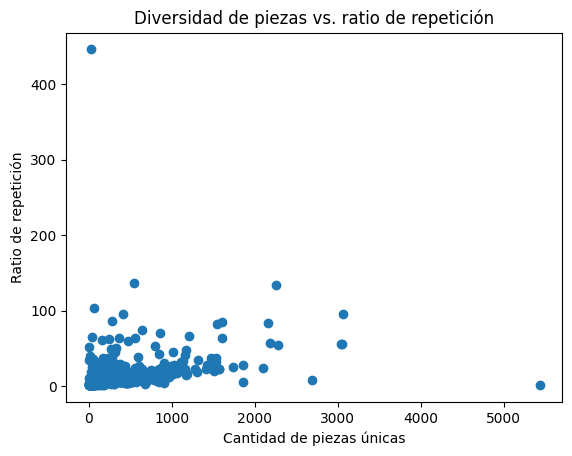

In [ ]:
plt.scatter(
    parts_per_theme["unique_parts"],
    parts_per_theme["repetition_ratio"]
)

plt.xlabel("Cantidad de piezas únicas")
plt.ylabel("Ratio de repetición")
plt.title("Diversidad de piezas vs. ratio de repetición")
plt.show()

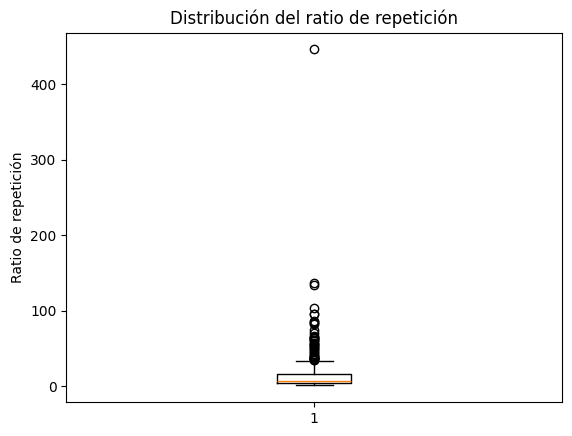

In [ ]:
plt.boxplot(parts_per_theme["repetition_ratio"])

plt.ylabel("Ratio de repetición")
plt.title("Distribución del ratio de repetición")
plt.show()

In [ ]:
q1 = parts_per_theme["repetition_ratio"].quantile(0.25)
q3 = parts_per_theme["repetition_ratio"].quantile(0.75)

iqr = q3 - q1

limite_inferior = q1 - 1.5 * iqr
limite_superior = q3 + 1.5 * iqr

outliers = parts_per_theme[
    (parts_per_theme["repetition_ratio"] < limite_inferior) |
    (parts_per_theme["repetition_ratio"] > limite_superior)
]

outliers.sort_values("repetition_ratio", ascending=False)

     theme_id                  theme_name  total_parts  unique_parts  \
131     277.0                      Mosaic        14712            33   
403     709.0                    LEGO Art        74599           544   
0         1.0                     Technic       301240          2258   
130     276.0                  Sculptures         6293            61   
220     467.0                       Basic        39946           416   
74      158.0                   Star Wars       291012          3061   
10       34.0               Make & Create        24378           283   
413     719.0  BrickLink Designer Program       137684          1609   
415     721.0                       Icons       182143          2165   
75      171.0   Ultimate Collector Series       128015          1548   
113     252.0                Architecture        47579           639   
294     577.0                   Minecraft        60456           861   
370     673.0              Creator Expert        81129          

## Analisis de outliers por IQR
Se observa un valor atípico especialmente marcado en el tema Mosaic, con un repetition_ratio de aproximadamente 445.8, muy por encima del resto de los temas. Otros temas como LEGO Art y Technic también presentan valores elevados, aunque considerablemente menores. Estos casos no se eliminaron, ya que representan comportamientos reales del dominio y aportan información relevante sobre la reutilización de piezas.

Además, vale la pena destacar que los outliers detectados se encuentran únicamente por encima del límite superior. Esto se debe a que el repetition_ratio se define como:

```total_parts / unique_parts```

y, dado que la cantidad total de piezas no puede ser menor que la cantidad de tipos de piezas únicas, el ratio no puede ser menor que 1. Por este motivo, no se esperan valores atípicos inferiores en esta variable.

## Conclusiones
A partir de los resultados obtenidos se observa que existen diferencias marcadas en el grado de reutilización de piezas entre los distintos temas. La métrica utilizada, repetition_ratio = total_parts / unique_parts, permite interpretar cuántas veces se reutiliza, en promedio, cada tipo de pieza dentro de un tema.
- Mosaic destaca ampliamente, con un repetition_ratio ≈ 445.8: usa 14712 piezas pero solo 33 tipos distintos. Esto indica una reutilización muy alta, coherente con sets basados en patrones y repetición visual.
- LEGO Art y Technic también presentan ratios altos, aunque con mayor variedad de piezas.
- Star Wars tiene un ratio cercano a 95.1, mostrando reutilización importante pero con más diversidad de piezas.
- Los ratios cercanos a 1 deben interpretarse con cuidado, porque algunos temas tienen muy pocas piezas o sets.

Por ahora no se eliminan estos casos extremos, pero más adelante convendría evaluar un filtro por cantidad mínima de sets o piezas para evitar conclusiones sesgadas por temas con muy poca información.

https://rebrickable.com/mocs/MOC-132733/BrickMeisterZ/the-simpsons-krusty-burger/#parts
![Ejemplo de Set con baja repeticion (Simpsons)](https://cdn.rebrickable.com/media/thumbs/mocs/moc-132733/177127.jpg/1000x800.jpg?1753208222.1109815)
![Partes de un set de Mosaico ](https://media.discordapp.net/attachments/1544799785112965170/1550545481841643571/image.png?ex=6aaeb982&is=6aad6802&hm=3b6ced8644b52a25aed42725df40cee10574336d4152aadcd1819418505bd5d4&=&format=webp&quality=lossless&width=1536&height=1424)

### Grafico de conclusiones
Aqui se puede apreciar los themes con mayor repetition rate

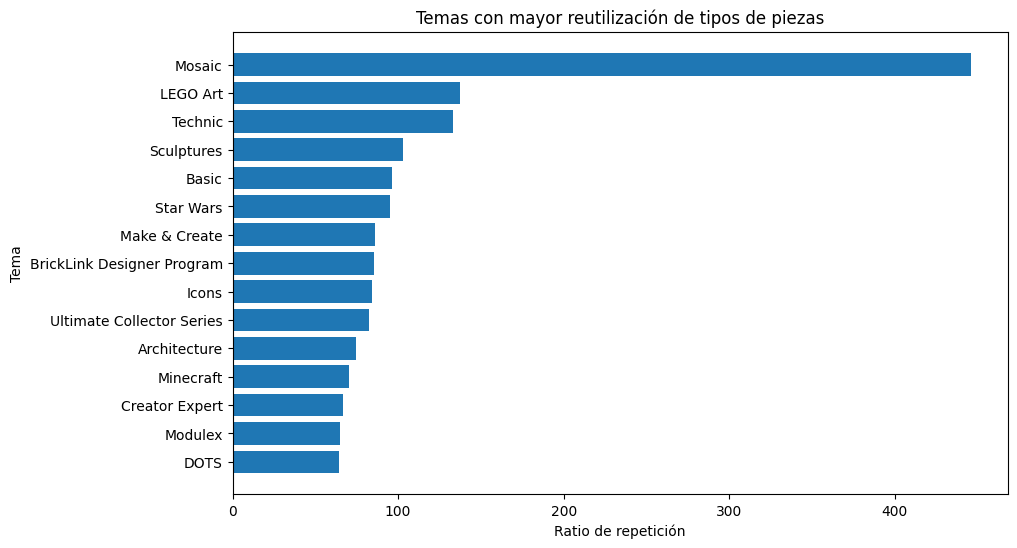

In [ ]:
top_themes = (
    parts_per_theme
    .sort_values("repetition_ratio", ascending=False)
    .head(15)
)

plt.figure(figsize=(10, 6))

plt.barh(
    top_themes["theme_name"],
    top_themes["repetition_ratio"]
)

plt.xlabel("Ratio de repetición")
plt.ylabel("Tema")
plt.title("Temas con mayor reutilización de tipos de piezas")

plt.gca().invert_yaxis()
plt.show()

# Ejercicio 1 - Pregunta 3
## ¿Qué porcentaje de minifiguras son reutilizadas en múltiples sets frente a aquellas que son exclusivas?



### Criterios metodológicos y tratamiento de datos
*   Selección de versión del inventario: Al igual que en las preguntas anteriores, tomamos únicamente la versión más reciente de cada inventario en inventories.csv para evitar duplicación de registros por revisiones históricas.

In [ ]:
inventarios_ultima_version = (
    ds_inventories_trabajo
    .sort_values('version')
    .drop_duplicates('set_num', keep='last')
)

inv_minifigs = ds_inventory_minifigs_trabajo.merge(
    inventarios_ultima_version[['id', 'set_num']],
    left_on='inventory_id',
    right_on='id',
    how='inner'
)

*   Filtro de minifiguras sin set: Excluimos aquellos inventarios que representan a minifiguras vendidas individualmente (identificadas por el prefijo fig- en set_num) y filtramos únicamente los sets confirmados presentes en sets.csv.

In [ ]:
inv_minifigs_sets = inv_minifigs.merge(
    ds_sets_trabajo[['set_num']],
    on='set_num',
    how='inner'
)

*   Métrica de exclusividad: Para cada minifigura, contamos la cantidad de sets únicos (set_num) en los que aparece. Clasificamos las minifiguras en exclusiva, si aparece en exactamente 1 set, o reutilizada, si aparece en 2 o más sets.

In [ ]:
minifigs_sets_count = (
    inv_minifigs_sets
    .groupby('fig_num')['set_num']
    .nunique()
    .reset_index(name='cant_sets')
)

minifigs_sets_count['categoria_exclusividad'] = np.where(
    minifigs_sets_count['cant_sets'] == 1,
    'Exclusiva',
    'Reutilizada'
)

### Analisis de distribución

Comencemos analizando el porcentaje de figuras exclusivas y reutilizadas.

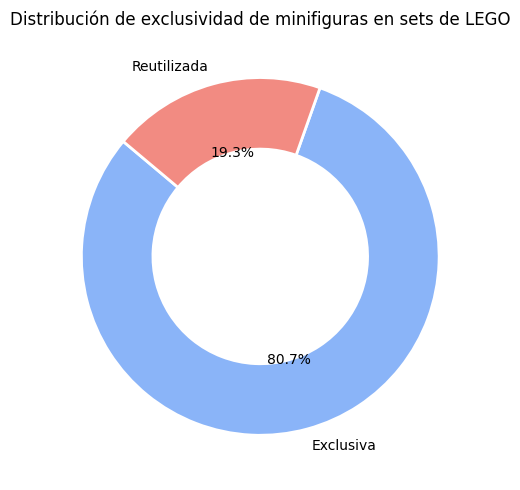

In [ ]:
resumen_exclusividad = (
    minifigs_sets_count['categoria_exclusividad']
    .value_counts()
    .reset_index()
)
resumen_exclusividad.columns = ['Categoría', 'Cantidad de Minifiguras']
resumen_exclusividad['Porcentaje (%)'] = (
    (resumen_exclusividad['Cantidad de Minifiguras'] / resumen_exclusividad['Cantidad de Minifiguras'].sum()) * 100
).round(2)

colors = ['#8ab4f8', '#f28b82']

plt.figure(figsize=(7, 5))
plt.pie(
    resumen_exclusividad['Cantidad de Minifiguras'],
    labels=resumen_exclusividad['Categoría'],
    autopct='%1.1f%%',
    startangle=140,
    colors=colors,
    wedgeprops=dict(width=0.4, edgecolor='white', linewidth=2)
)
plt.title('Distribución de exclusividad de minifiguras en sets de LEGO')
plt.tight_layout()
plt.show()

El gráfico muestra que la gran mayoría de las minifiguras son exclusivas de un set. Esto puede deberse a estrategias de diseño o comercialización propias de LEGO orientadas al coleccionismo, donde la exclusividad es muy importante, pero hay otro factor importante a tener en cuenta.

La posibilidad de reutilizar minifiguras está condicionada por el volumen de la temática. En general, solo aquellas tematicas con gran cantidad de sets podrian justificar la reutilización de figuras.

Cabe destacar que hay minifiguras genericas que no pertenecena una temática particular. Naturalmente, se espera que estas piezas tengan un alto grado de reutilización.

Para darle un poco mas de sustento a estas suposiciones, analicemos las minifiguras más reutilizadas para intentar encontrar algun patrón.

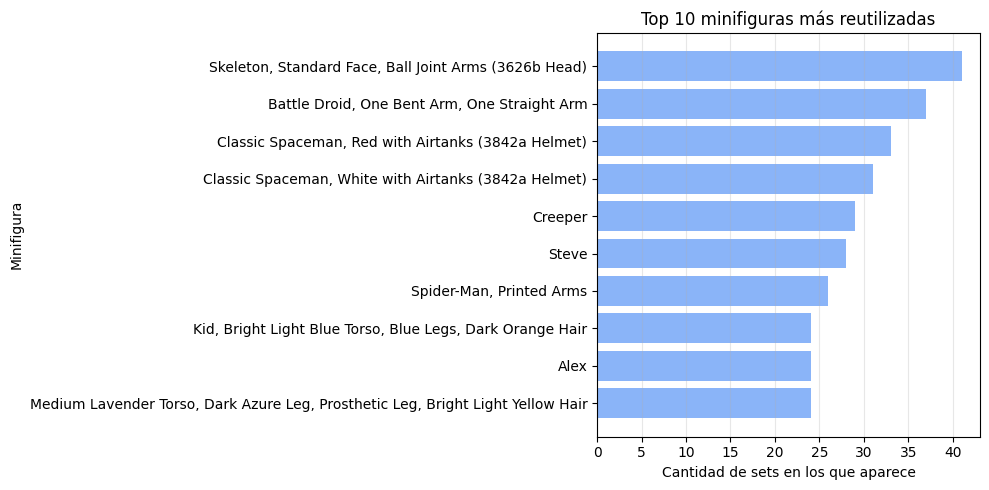

In [ ]:
top_minifigs = (
    minifigs_sets_count
    .sort_values('cant_sets', ascending=False)
    .head(10)
    .merge(ds_minifigs_trabajo[['fig_num', 'name']], on='fig_num', how='left')
)

plt.figure(figsize=(10, 5))
plt.barh(top_minifigs['name'], top_minifigs['cant_sets'], color='#8ab4f8')
plt.xlabel('Cantidad de sets en los que aparece')
plt.ylabel('Minifigura')
plt.title('Top 10 minifiguras más reutilizadas')
plt.gca().invert_yaxis()
plt.grid(axis='x', alpha=0.3)
plt.tight_layout()
plt.show()

Puede verse que las figuras más reutilizadas pertenecen a temáticas históricas, populares y con una producción masiva de sets (como City/Town, Space, Castle, Star Wars o Minecraft).

## Conclusiones

El análisis muestra una predominancia de la exclusividad de minifiguras LEGO: el **80.3%** de las figuras son exclusivas de un único set, mientras que solo el **19.7%** reaparece en dos o más.

La reutilización responde a dos patrones claros:
* **Elementos de escenario y personajes genéricos (NPCs):** Esqueletos, policías, bomberos o astronautas clásicos que funcionan como elementos estándar de construcción de escenario dentro de la misma temática.
* **Protagonistas recurrentes:** Personajes principales recurrentes: Personajes centrales que encabezan múltiples sets a lo largo de los años.

En síntesis, la reutilización suele ser aplicada a figuras genéricas o emblemáticas de alguna temática determinada, siendo la excepción a la regla en el mundo de las minifiguras LEGO donde la exclusividad es un factor muy importante para el coleccionismo.

# Ejercicio 1 - Pregunta 4
## ¿Los sets con más piezas usan también más colores distintos? ¿Esa relación cambia según el tema y la época?

Una idea habitual es que un set más grande es también un set más variado. Sin embargo, un set de gran tamaño puede estar construido casi en su totalidad con pocos colores (por ejemplo, un edificio gris), mientras que uno pequeño puede ser muy colorido. Además, la paleta de colores de LEGO se amplió con los años y no todos los temas utilizan los mismos colores. Por eso se analiza la relación entre el tamaño del set y su variedad de colores, y si esta cambia entre temas y décadas.

##Datasets adicionales utilizados:
- colors.csv: `inventory_parts` solo contiene el identificador del color. Con este dataset se identifica si un color es transparente (`is_trans`).
- parts.csv: permite conocer la categoría de cada pieza (`part_cat_id`), con la que se mide la variedad de tipos de pieza de cada set.

## Construcción del dataset por set

`inventory_parts` tiene una fila por cada combinación de inventario, pieza y color. Para obtener una fila por set:

- Se utilizó únicamente la última versión de cada inventario.
- Se excluyeron las piezas de repuesto (`is_spare`), ya que no forman parte del modelo armado.
- Al unir con `sets` mediante un `inner join` quedaron afuera los inventarios de minifiguras (`fig-`).
- Se excluyeron los colores `-1` (Unknown) y `9999` (No Color/Any Color), que no son colores reales.

In [ ]:
# Última versión de cada inventario
inventarios_ultima_version = (
    ds_inventories_trabajo
    .sort_values('version')
    .drop_duplicates('set_num', keep='last')
)

# Los booleanos de Rebrickable pueden venir como 't'/'f' o como True/False
def es_verdadero(serie):
    return serie.astype(str).str.lower().isin(['t', 'true', '1'])

# Detalle de piezas sin repuestos
detalle = ds_inventory_parts_trabajo.copy()
if 'is_spare' in detalle.columns:
    detalle = detalle[~es_verdadero(detalle['is_spare'])]

# Set al que pertenece cada fila, con su año y tema
detalle = detalle.merge(
    inventarios_ultima_version[['id', 'set_num']],
    left_on='inventory_id',
    right_on='id',
    how='inner'
).drop(columns='id')

detalle = detalle.merge(
    ds_sets_trabajo[['set_num', 'year', 'theme_id']],
    on='set_num',
    how='inner'
)

# Datasets adicionales: colors (si el color es transparente) y parts (categoría de la pieza)
detalle = detalle.merge(
    ds_colors_trabajo[['id', 'is_trans']].rename(columns={'id': 'color_id'}),
    on='color_id',
    how='left'
)

detalle = detalle.merge(
    ds_parts_trabajo[['part_num', 'part_cat_id']],
    on='part_num',
    how='left'
)

# Colores que no son colores reales
detalle = detalle[~detalle['color_id'].isin([-1, 9999])]

print("Filas del detalle:", len(detalle))
print("Sets distintos:", detalle['set_num'].nunique())

Filas del detalle: 1234728
Sets distintos: 19606


### Datos faltantes

Al unir las tablas pueden aparecer valores faltantes, por ejemplo una pieza que no figura en `parts.csv` o un color que no figura en `colors.csv`. Se contó la cantidad de valores nulos en las columnas utilizadas:

In [ ]:
detalle[['year', 'theme_id', 'color_id', 'is_trans', 'part_cat_id', 'quantity']].isna().sum()

,0
year,0
theme_id,0
color_id,0
is_trans,0
part_cat_id,0
quantity,0


No se encontraron valores nulos en las columnas utilizadas (año, tema, color, categoría de la pieza y cantidad) luego de las uniones, por lo que no fue necesario imputar valores ni descartar filas. De todas formas se mantiene el `dropna` sobre `is_trans` como resguardo, ya que no sería posible estimar razonablemente el color de una pieza que no figure en `colors.csv`.

In [ ]:
detalle = detalle.dropna(subset=['is_trans'])
detalle['es_trans'] = es_verdadero(detalle['is_trans'])

## Cálculo de variables por set

Se agruparon las filas por set y se calcularon las siguientes variables derivadas:

- num_piezas: cantidad total de piezas del set.
- piezas_unicas: cantidad de tipos de pieza distintos.
- n_colores: cantidad de colores distintos.
- n_categorias: cantidad de categorías de pieza distintas.
- pct_transparentes: porcentaje de piezas con color transparente.
- decada: década de lanzamiento del set.
- tamano: categoría de tamaño (hasta 50, de 51 a 200, de 201 a 1000 y más de 1000 piezas).
- log_piezas y log_piezas_unicas: logaritmo en base 10 de num_piezas y de piezas_unicas. Comprime los valores grandes y deja la variable más pareja (sería como pensar cuantas veces se multiplica por 10).

Se excluyeron los sets con menos de 10 piezas, ya que un set de muy pocas piezas tiene necesariamente muy pocos colores y esto solo agrega ruido a la comparación.

In [ ]:
MIN_PIEZAS = 10

detalle['piezas_transparentes'] = detalle['quantity'] * detalle['es_trans']

ds_q4 = (
    detalle
    .groupby('set_num')
    .agg(
        num_piezas=('quantity', 'sum'),
        piezas_unicas=('part_num', 'nunique'),
        n_colores=('color_id', 'nunique'),
        n_categorias=('part_cat_id', 'nunique'),
        piezas_transparentes=('piezas_transparentes', 'sum'),
        year=('year', 'first'),
        theme_id=('theme_id', 'first'),
    )
    .reset_index()
)

ds_q4['pct_transparentes'] = ds_q4['piezas_transparentes'] / ds_q4['num_piezas'] * 100
ds_q4['decada'] = (ds_q4['year'] // 10 * 10).astype(int)
ds_q4['tamano'] = pd.cut(
    ds_q4['num_piezas'],
    bins=[0, 50, 200, 1000, np.inf],
    labels=['Chico (≤50)', 'Mediano (51-200)', 'Grande (201-1000)', 'Muy grande (>1000)']
)

# Nombre del tema
ds_q4 = ds_q4.merge(
    ds_themes_trabajo[['id', 'name']].rename(columns={'id': 'theme_id', 'name': 'tema'}),
    on='theme_id',
    how='left'
)

# Sets con muy pocas piezas
ds_q4_completo = ds_q4
ds_q4 = ds_q4[ds_q4['num_piezas'] >= MIN_PIEZAS].copy()

# Transformación logarítmica para reducir la asimetría
ds_q4['log_piezas'] = np.log10(ds_q4['num_piezas'])
ds_q4['log_piezas_unicas'] = np.log10(ds_q4['piezas_unicas'])

print("Sets descartados por tener menos de", MIN_PIEZAS, "piezas:", len(ds_q4_completo) - len(ds_q4))
print("Sets en el análisis:", len(ds_q4))

Sets descartados por tener menos de 10 piezas: 3624
Sets en el análisis: 15982


In [ ]:
ds_q4[['num_piezas', 'piezas_unicas', 'n_colores', 'n_categorias', 'pct_transparentes']].describe().round(2)

       num_piezas  piezas_unicas  n_colores  n_categorias  pct_transparentes
count    15982.00       15982.00   15982.00      15982.00           15982.00
mean       282.19          56.53      11.56         14.62               5.46
std        549.13          60.10       7.91         10.48               9.15
min         10.00           1.00       1.00          1.00               0.00
25%         36.00          16.00       6.00          6.00               0.00
50%         95.00          33.00       9.00         13.00               2.63
75%        295.00          79.00      15.00         22.00               7.44
max      11695.00         655.00      57.00         53.00             100.00

### Valores atípicos

Se utilizó el criterio del rango intercuartílico (IQR) para identificar valores atípicos en `num_piezas` y `n_colores`.

In [ ]:
def contar_atipicos(serie):
    Q1 = serie.quantile(0.25)
    Q3 = serie.quantile(0.75)
    IQR = Q3 - Q1
    limite_inferior = Q1 - 1.5 * IQR
    limite_superior = Q3 + 1.5 * IQR
    return pd.Series({
        'Q1': Q1,
        'Q3': Q3,
        'limite_inferior': limite_inferior,
        'limite_superior': limite_superior,
        'atipicos_inferiores': (serie < limite_inferior).sum(),
        'atipicos_superiores': (serie > limite_superior).sum(),
    })

pd.DataFrame({
    'num_piezas': contar_atipicos(ds_q4['num_piezas']),
    'n_colores': contar_atipicos(ds_q4['n_colores']),
}).round(2)

                     num_piezas  n_colores
Q1                         36.0        6.0
Q3                        295.0       15.0
limite_inferior          -352.5       -7.5
limite_superior           683.5       28.5
atipicos_inferiores         0.0        0.0
atipicos_superiores      1681.0      678.0

Se encontraron 1.681 valores atípicos en `num_piezas` y 678 en `n_colores`, todos correspondientes al extremo superior de la distribución (por encima de 683,5 piezas y de 28,5 colores). No hay atípicos inferiores.

Estos valores no fueron eliminados, ya que corresponden a sets reales con una cantidad elevada de piezas y de colores (el máximo es de 11.695 piezas y 57 colores). Debido a la fuerte asimetría de `num_piezas`, se utilizó una escala logarítmica en las visualizaciones. Como chequeo de coherencia se verificó que ningún set tenga más colores distintos que piezas:

In [ ]:
print("Sets con más colores que piezas:", (ds_q4['n_colores'] > ds_q4['num_piezas']).sum())

Sets con más colores que piezas: 0


### Exploración y relación entre variables

Se analizaron las variables:

- Cuantitativas: `num_piezas` y `n_colores`.
- Cualitativas: `tamano` y `tema`.

Para estudiar la relación entre el tamaño y la cantidad de colores se utilizó un gráfico de dispersión y el coeficiente de correlación de Pearson, que mide cuán relacionadas están dos variables de forma lineal: vale 1 si la relación lineal positiva es perfecta, 0 si no existe correlación y −1 si la relación negativa es perfecta.

Como Pearson solo detecta relaciones lineales y es sensible a los valores atípicos, y `num_piezas` es una variable muy asimétrica, se aplicó una transformación logarítmica para reducir el sesgo (`log_piezas`). En el gráfico de dispersión, con escala logarítmica en el eje horizontal, la relación se ve aproximadamente lineal, por lo que Pearson es adecuado sobre la variable transformada. Se calcula también sobre la variable original para comparar.

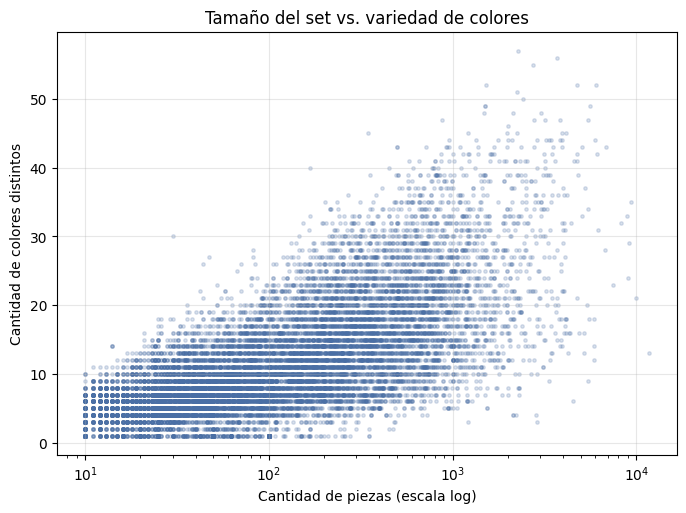

Correlación de Pearson entre num_piezas y n_colores: 0.528
Correlación de Pearson entre log_piezas y n_colores: 0.689


In [ ]:
plt.figure(figsize=(8, 5.5))
plt.scatter(ds_q4['num_piezas'], ds_q4['n_colores'], s=6, alpha=0.2, color='#4a6fa5')
plt.xscale('log')
plt.xlabel('Cantidad de piezas (escala log)')
plt.ylabel('Cantidad de colores distintos')
plt.title('Tamaño del set vs. variedad de colores')
plt.grid(alpha=0.3)
plt.show()

r_original = ds_q4['num_piezas'].corr(ds_q4['n_colores'])
r_log = ds_q4['log_piezas'].corr(ds_q4['n_colores'])
print(f"Correlación de Pearson entre num_piezas y n_colores: {r_original:.3f}")
print(f"Correlación de Pearson entre log_piezas y n_colores: {r_log:.3f}")

Además, se compararon los sets según su categoría de tamaño mediante un diagrama de caja, y se calcularon la media y la mediana de colores de cada grupo:

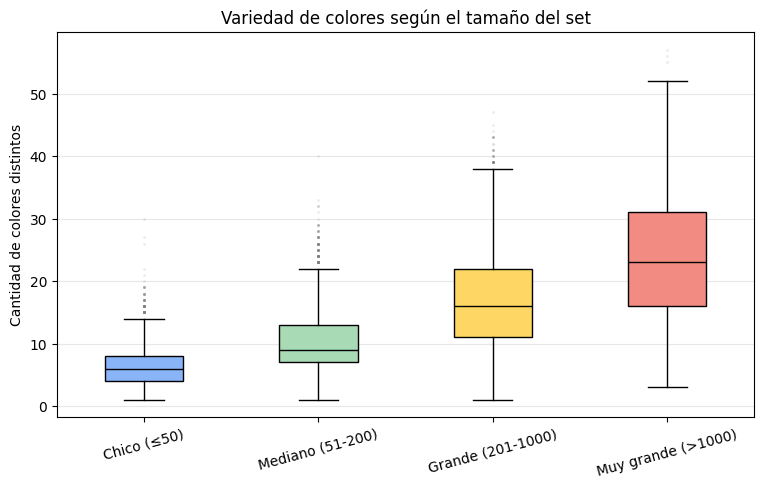

In [ ]:
grupos = [ds_q4.loc[ds_q4['tamano'] == t, 'n_colores'] for t in ds_q4['tamano'].cat.categories]

plt.figure(figsize=(9, 5))
bp = plt.boxplot(
    grupos,
    patch_artist=True,
    flierprops=dict(marker='o', ms=2, alpha=0.15, mfc='gray', mec='none')
)

for p, c in zip(bp['boxes'], ['#8ab4f8', '#a8dab5', '#fdd663', '#f28b82']):
    p.set_facecolor(c)

for m in bp['medians']:
    m.set_color('black')

plt.xticks(range(1, len(grupos) + 1), ds_q4['tamano'].cat.categories, rotation=15)
plt.ylabel('Cantidad de colores distintos')
plt.title('Variedad de colores según el tamaño del set')
plt.grid(axis='y', alpha=0.3)
plt.show()

In [ ]:
resultado = (
    ds_q4
    .groupby('tamano', observed=True)['n_colores']
    .agg(['count', 'mean', 'median'])
    .round(2)
)

resultado

                    count   mean  median
tamano                                  
Chico (≤50)          5587   6.21     6.0
Mediano (51-200)     5035  10.34     9.0
Grande (201-1000)    4441  17.09    16.0
Muy grande (>1000)    919  23.99    23.0

Los sets pasan de una mediana de 6 colores en la categoría "Chico" a 23 en la categoría "Muy grande" (9 en los medianos y 16 en los grandes). La correlación de Pearson entre `num_piezas` y `n_colores` es de 0,53, y sube a 0,69 al utilizar el logaritmo de las piezas (`log_piezas`). Esto confirma que la relación es lineal en escala logarítmica y no en la escala original, y que entre ambas variables existe una asociación positiva y fuerte.

En el gráfico de dispersión se observa que la nube de puntos crece con el tamaño, pero con mucha dispersión: para una misma cantidad de piezas hay sets con pocos y con muchos colores. Además, el crecimiento se desacelera: como el eje horizontal es logarítmico, cada vez que se duplica la cantidad de piezas la mediana de colores aumenta aproximadamente entre 3 y 4.

También se calculó la correlación entre las variables de variedad:

In [ ]:
ds_q4[['log_piezas', 'log_piezas_unicas', 'n_colores', 'n_categorias', 'pct_transparentes']].corr().round(2)

                   log_piezas  log_piezas_unicas  n_colores  n_categorias  \
log_piezas               1.00               0.81       0.69          0.77   
log_piezas_unicas        0.81               1.00       0.75          0.87   
n_colores                0.69               0.75       1.00          0.76   
n_categorias             0.77               0.87       0.76          1.00   
pct_transparentes       -0.10              -0.02       0.03          0.01   

                   pct_transparentes  
log_piezas                     -0.10  
log_piezas_unicas              -0.02  
n_colores                       0.03  
n_categorias                    0.01  
pct_transparentes               1.00  

En la matriz se observa que `n_colores` está algo más correlacionado con `log_piezas_unicas` (0,75) y con `n_categorias` (0,76) que con `log_piezas` (0,69). Es decir, la cantidad de colores acompaña un poco más a la cantidad de tipos de pieza distintos que al tamaño del set en sí. `pct_transparentes` prácticamente no está correlacionado con el resto de las variables (entre −0,10 y 0,03), por lo que no aporta información sobre el tamaño ni sobre la variedad.

### Análisis por tema

Para ver si la relación cambia según el tema, se calculó la mediana de piezas y de colores de cada tema. Se consideraron únicamente los temas con al menos 30 sets, para no sacar conclusiones de temas con muy pocos datos. Los temas que quedan por encima del resto utilizan más colores de los que les correspondería por su tamaño.

In [ ]:
MIN_SETS_TEMA = 30

por_tema = (
    ds_q4
    .groupby('tema')
    .agg(
        n_sets=('set_num', 'count'),
        piezas_mediana=('num_piezas', 'median'),
        colores_mediana=('n_colores', 'median'),
    )
    .query('n_sets >= @MIN_SETS_TEMA')
    .sort_values('colores_mediana', ascending=False)
)

print("Temas considerados:", len(por_tema))
pd.concat([por_tema.head(10), por_tema.tail(10)])

Temas considerados: 120


                               n_sets  piezas_mediana  colores_mediana
tema                                                                  
BrickLink Designer Program         63          2178.0             31.0
Classic                            67           484.0             27.0
Elves                              41           303.0             26.0
Disney                             74           474.0             24.0
Monkie Kid                         57           749.0             24.0
Chinese Traditional Festivals      34           669.0             21.0
Icons                              86          1427.5             21.0
LEGO Ideas and CUUSOO             103           899.0             21.0
Minecraft                         181           251.0             20.0
Disney Princess                   128           108.0             19.5
Clocks and Watches                101            27.0              5.0
Classic Space                      83            74.0              5.0
Vehicl

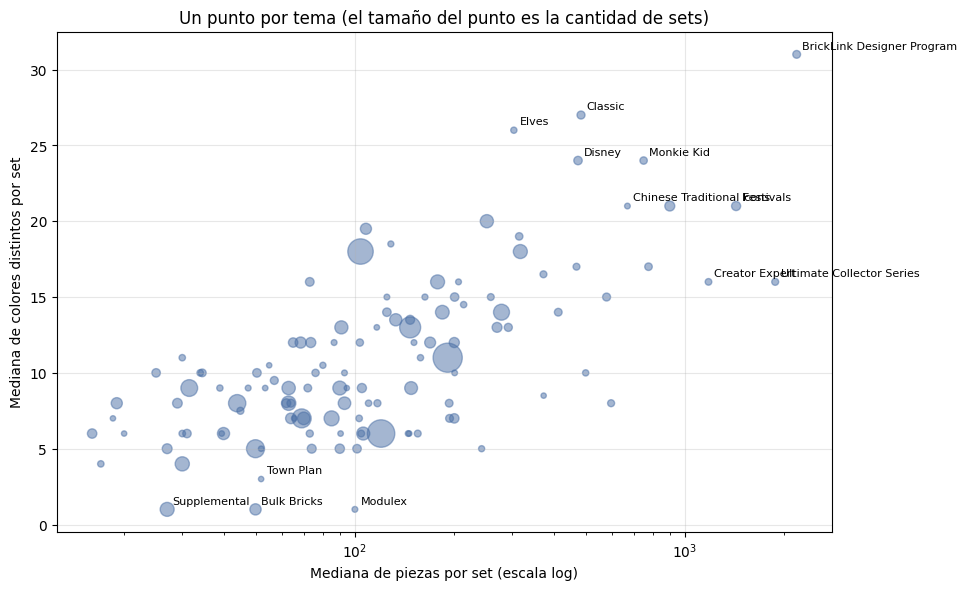

In [ ]:
plt.figure(figsize=(10, 6.5))
plt.scatter(
    por_tema['piezas_mediana'],
    por_tema['colores_mediana'],
    s=por_tema['n_sets'] / 2,
    alpha=0.5,
    color='#4a6fa5'
)
plt.xscale('log')

# Se rotulan solo los temas más extremos para que se pueda leer
a_rotular = pd.concat([
    por_tema.nlargest(6, 'colores_mediana'),
    por_tema.nsmallest(4, 'colores_mediana'),
    por_tema.nlargest(4, 'piezas_mediana'),
]).drop_duplicates()

for nombre, fila in a_rotular.iterrows():
    plt.annotate(nombre, (fila['piezas_mediana'], fila['colores_mediana']),
                 fontsize=8, xytext=(4, 4), textcoords='offset points')

plt.xlabel('Mediana de piezas por set (escala log)')
plt.ylabel('Mediana de colores distintos por set')
plt.title('Un punto por tema (el tamaño del punto es la cantidad de sets)')
plt.grid(alpha=0.3)
plt.show()

Como los temas con sets grandes tienen más colores simplemente por su tamaño, se calculó además cuántos colores más o menos usa cada set respecto de la mediana de su categoría de tamaño. Luego se tomó la mediana de esa diferencia por tema:

In [ ]:
ds_q4['mediana_tamano'] = ds_q4.groupby('tamano', observed=True)['n_colores'].transform('median')
ds_q4['exceso_colores'] = ds_q4['n_colores'] - ds_q4['mediana_tamano']

exceso_tema = (
    ds_q4
    .groupby('tema')
    .agg(n_sets=('set_num', 'count'), exceso_mediano=('exceso_colores', 'median'))
    .query('n_sets >= @MIN_SETS_TEMA')
    .sort_values('exceso_mediano')
)

pd.concat([exceso_tema.head(8), exceso_tema.tail(8)])

                            n_sets  exceso_mediano
tema                                              
Expert Builder                  39           -10.0
Architecture                    51            -8.0
Modulex                         35            -8.0
Make & Create                   41            -6.0
Ultimate Collector Series       50            -6.0
Ferrari                         30            -5.0
Creator Expert                  46            -5.0
Bulk Bricks                    132            -5.0
Disney                          74             8.0
Friends                        671             8.0
Monkie Kid                      57             8.0
BrickLink Designer Program      63             9.0
Disney Princess                128             9.0
Frozen                          38             9.0
Elves                           41            11.0
Classic                         67            11.0

Los temas con mayor cantidad mediana de colores son BrickLink Designer Program (31), Classic (27), Elves (26), Disney (24) y Monkie Kid (24), todos con sets de tamaño medio o grande. Entre los de menor cantidad aparecen Bulk Bricks, Modulex y Supplemental (1 color de mediana), que no son sets de construcción convencionales sino bolsas de piezas sueltas o surtidos de un solo color, por lo que conviene interpretarlos con cuidado.

Al descontar el efecto del tamaño, los temas que usan más colores de los que les corresponderían son Elves (+11), Classic (+11), Disney Princess (+9), BrickLink Designer Program (+9), Frozen (+9), Friends (+8), Disney (+8) y Monkie Kid (+8). Los que usan menos son Expert Builder (−10), Architecture (−8), Modulex (−8), Make & Create (−6), Ultimate Collector Series (−6), Creator Expert (−5) y Ferrari (−5). Esto es coherente con el dominio: los temas orientados a personajes y escenas (Friends, Disney, Frozen, Elves) utilizan paletas variadas, mientras que los de modelos de colección o réplicas (Architecture, Ultimate Collector Series, Ferrari) suelen construirse con pocos colores aun siendo sets grandes.

### Análisis por época

Se agruparon los sets por década y se calculó la mediana de piezas y de colores, dejando afuera las décadas con menos de 20 sets.

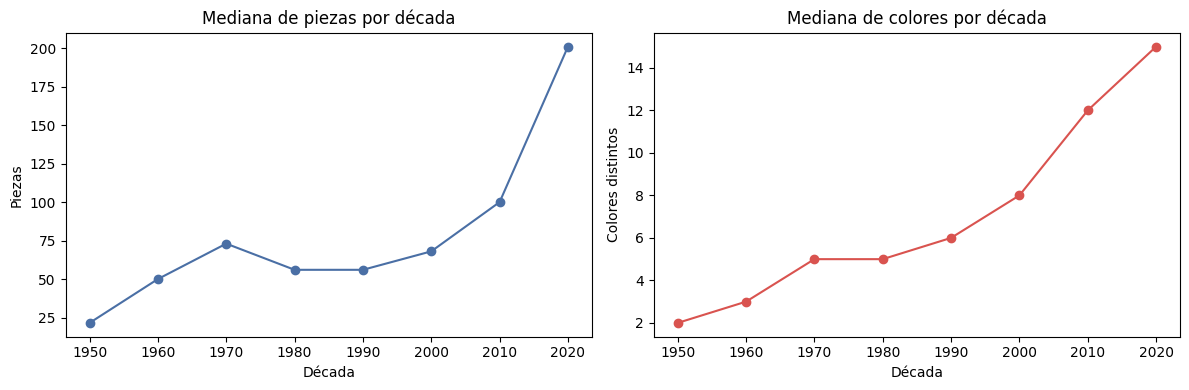

        n_sets  piezas_mediana  colores_mediana
decada                                         
1950        72            21.5              2.0
1960       292            50.0              3.0
1970       529            73.0              5.0
1980       874            56.0              5.0
1990      1765            56.0              6.0
2000      3126            68.0              8.0
2010      4849           100.0             12.0
2020      4470           201.0             15.0

In [ ]:
por_decada = (
    ds_q4
    .groupby('decada')
    .agg(
        n_sets=('set_num', 'count'),
        piezas_mediana=('num_piezas', 'median'),
        colores_mediana=('n_colores', 'median'),
    )
    .query('n_sets >= 20')
)

fig, ejes = plt.subplots(1, 2, figsize=(12, 4))

ejes[0].plot(por_decada.index, por_decada['piezas_mediana'], marker='o', color='#4a6fa5')
ejes[0].set_title('Mediana de piezas por década')
ejes[0].set_xlabel('Década')
ejes[0].set_ylabel('Piezas')

ejes[1].plot(por_decada.index, por_decada['colores_mediana'], marker='o', color='#d9534f')
ejes[1].set_title('Mediana de colores por década')
ejes[1].set_xlabel('Década')
ejes[1].set_ylabel('Colores distintos')

plt.tight_layout()
plt.show()

por_decada.round(1)

## Conclusión

Los sets con más piezas utilizan, en general, una mayor cantidad de colores distintos. La mediana de colores pasa de 6 en los sets chicos a 23 en los muy grandes, y la correlación de Pearson entre el logaritmo de las piezas y la cantidad de colores es de 0,69 (0,53 sin aplicar el logaritmo).

Sin embargo, el tamaño explica solo una parte de la variedad de colores. La relación no se estabiliza, pero se desacelera: cada vez que se duplica la cantidad de piezas, la mediana de colores aumenta aproximadamente entre 3 y 4. Además, existen sets grandes con pocos colores y sets chicos muy coloridos. De hecho, la cantidad de colores acompaña algo más a la cantidad de tipos de pieza distintos (correlación de 0,75) y de categorías de pieza (0,76) que al tamaño total del set (0,69).

Por tema, los más coloridos respecto de su tamaño son Elves, Classic, Disney Princess, BrickLink Designer Program y Frozen, y los menos coloridos son Expert Builder, Architecture, Modulex y Make & Create. Por época, entre la década de 1950 y la de 2020 la mediana de colores pasó de 2 a 15, mientras que la de piezas pasó de 21,5 a 201. Es llamativo que entre las décadas de 1970 y 2000 la mediana de piezas se mantuvo entre 56 y 73 y aun así la de colores pasó de 5 a 8, lo que sugiere que la ampliación de la paleta no depende solo de que los sets sean más grandes.

Cabe aclarar que solo se consideraron las piezas del set en sí, sin sumar las de sus sub-sets, y que se excluyeron los sets de menos de 10 piezas (3.624 sets, quedando 15.982 para el análisis) y los temas de menos de 30 sets. Además, que dos variables estén asociadas no implica que una cause la otra.

# Ejercicio 1 - Agrupamiento (K-Means)

Hasta acá el análisis se hizo con preguntas definidas de antemano. En esta sección
se busca lo contrario: determinar si los sets se agrupan naturalmente en categorías
que no fueron definidas previamente, utilizando el algoritmo K-Means.

La unidad de análisis es el **set**: cada observación es un set completo, descrito
por un conjunto de variables numéricas que resumen su composición. El objetivo no
es predecir ninguna variable, sino detectar si existen grupos de sets con
características similares entre sí y diferentes del resto.

## Construcción del dataset analítico

Se parte de `inventory_parts`, que tiene una fila por cada combinación de
inventario, pieza y color, y se agrega a nivel de set. Se aplican los mismos
criterios metodológicos usados en la Pregunta 4, para que todo el ejercicio
trabaje sobre la misma base:

- Se utiliza únicamente la última versión del inventario de cada set.
- Se excluyen las piezas de repuesto (`is_spare`), que no forman parte del modelo armado.
- Se excluyen los colores -1 (Unknown) y 9999 (No Color), que no son colores reales.
- Se excluyen los sets con menos de 10 piezas, por tratarse de accesorios,
  promocionales o figuras sueltas y no de modelos de construcción.
- Al unir con `sets` mediante un inner join quedan afuera los inventarios de
  minifiguras (prefijo `fig-`).

Se utilizan como datasets adicionales `colors.csv` (para identificar colores
transparentes) y `parts.csv` (para la categoría de cada pieza), los mismos que
incorpora la Pregunta 4.

In [ ]:
def es_verdadero(serie):
    """Los booleanos de Rebrickable pueden venir como 't'/'f' o como True/False."""
    return serie.astype(str).str.lower().isin(['t', 'true', '1'])

inventarios_ultima_version = (
    ds_inventories_trabajo
    .sort_values('version')
    .drop_duplicates('set_num', keep='last')
)

# Detalle de piezas, sin repuestos
detalle_cl = ds_inventory_parts_trabajo.copy()
detalle_cl = detalle_cl[~es_verdadero(detalle_cl['is_spare'])]

# Set al que pertenece cada fila, con su año y tema
detalle_cl = detalle_cl.merge(
    inventarios_ultima_version[['id', 'set_num']],
    left_on='inventory_id', right_on='id', how='inner'
).drop(columns='id')

detalle_cl = detalle_cl.merge(
    ds_sets_trabajo[['set_num', 'year', 'theme_id']],
    on='set_num', how='inner'
)

# Datasets adicionales: categoría de la pieza y si el color es transparente
detalle_cl = detalle_cl.merge(
    ds_parts_trabajo[['part_num', 'part_cat_id']], on='part_num', how='left'
)

detalle_cl = detalle_cl.merge(
    ds_colors_trabajo[['id', 'is_trans']].rename(columns={'id': 'color_id'}),
    on='color_id', how='left'
)

# Colores que no representan colores reales
detalle_cl = detalle_cl[~detalle_cl['color_id'].isin([-1, 9999])]

# Agregación a nivel de set
agrupado = detalle_cl.groupby('set_num')

ds_cluster = pd.DataFrame({
    'num_piezas'   : agrupado['quantity'].sum(),
    'piezas_unicas': agrupado['part_num'].nunique(),
    'n_colores'    : agrupado['color_id'].nunique(),
    'n_categorias' : agrupado['part_cat_id'].nunique(),
})

piezas_transparentes = (
    detalle_cl[es_verdadero(detalle_cl['is_trans'])]
    .groupby('set_num')['quantity'].sum()
)

ds_cluster['pct_transparentes'] = (
    piezas_transparentes / ds_cluster['num_piezas']
).fillna(0)

ds_cluster = ds_cluster.join(
    ds_sets_trabajo.set_index('set_num')[['name', 'year', 'theme_id']]
)

ds_cluster = ds_cluster[ds_cluster['num_piezas'] >= 10]

print('Sets en el dataset de agrupamiento:', len(ds_cluster))
print('Valores nulos:', ds_cluster.isna().sum().sum())

Sets en el dataset de agrupamiento: 15982
Valores nulos: 0


## Selección y transformación de variables

Las variables disponibles a nivel de set (`num_piezas`, `piezas_unicas`,
`n_colores`, `n_categorias`) presentan correlaciones de entre 0,53 y 0,87 entre sí.
Esto era esperable desde el dominio: un set más grande tiende a tener más tipos de
pieza, más colores y más categorías. Las cuatro variables están midiendo,
en buena medida, la misma dimensión subyacente: el tamaño del set.

Esto es un problema para K-Means. El algoritmo asigna cada observación al centro
más cercano, y la distancia se calcula sumando las diferencias en todas las
variables. Si cuatro de las variables expresan el tamaño, el tamaño pesa cuatro
veces en el cálculo y las demás características una sola. El resultado sería un
agrupamiento determinado casi exclusivamente por el tamaño, que no aporta
información nueva: para obtener grupos de sets chicos, medianos y grandes no hace
falta un algoritmo de agrupamiento.

Para evitarlo se transforman las variables de conteo en variables **relativas**,
que expresan proporciones en lugar de cantidades absolutas. Las cinco variables
finales son:

| Variable | Qué mide | Cálculo |
|---|---|---|
| `log_piezas` | Tamaño del set | log10(num_piezas) |
| `log_ratio` | Cuántas veces se repite, en promedio, cada tipo de pieza | log10(num_piezas / piezas_unicas) |
| `colores_por_tipo` | Variedad cromática relativa al tamaño | n_colores / piezas_unicas |
| `cats_por_tipo` | Variedad de tipos de pieza relativa al tamaño | n_categorias / piezas_unicas |
| `pct_transparentes` | Proporción de piezas transparentes | piezas transparentes / num_piezas |

Se aplica logaritmo en base 10 a las dos primeras por la fuerte asimetría de la
distribución, del mismo modo que se hizo en las preguntas anteriores.

Con estas cinco variables la correlación máxima entre pares baja de 0,87 a 0,53.
El tamaño sigue representado, pero deja de dominar el cálculo de distancias.

Se decidió **no incluir el año** entre las variables de agrupamiento. Al ser una
variable de rango amplio y fuerte estructura temporal, tendería a particionar los
grupos por década, lo que respondería una pregunta distinta de la planteada.
El año se utiliza más adelante, en la caracterización, para describir los grupos
obtenidos.

In [ ]:
ds_cluster['ratio_repeticion'] = ds_cluster['num_piezas'] / ds_cluster['piezas_unicas']

ds_cluster['log_piezas']       = np.log10(ds_cluster['num_piezas'])
ds_cluster['log_ratio']        = np.log10(ds_cluster['ratio_repeticion'])
ds_cluster['colores_por_tipo'] = ds_cluster['n_colores']    / ds_cluster['piezas_unicas']
ds_cluster['cats_por_tipo']    = ds_cluster['n_categorias'] / ds_cluster['piezas_unicas']

variables_cluster = [
    'log_piezas', 'log_ratio', 'colores_por_tipo', 'cats_por_tipo', 'pct_transparentes'
]

print('Correlación entre las variables de conteo originales:')
display(ds_cluster[['num_piezas', 'piezas_unicas', 'n_colores', 'n_categorias']].corr().round(2))

print('Correlación entre las variables finales:')
display(ds_cluster[variables_cluster].corr().round(2))

Correlación entre las variables de conteo originales:


               num_piezas  piezas_unicas  n_colores  n_categorias
num_piezas           1.00           0.74       0.53          0.54
piezas_unicas        0.74           1.00       0.78          0.87
n_colores            0.53           0.78       1.00          0.76
n_categorias         0.54           0.87       0.76          1.00

Correlación entre las variables finales:


                   log_piezas  log_ratio  colores_por_tipo  cats_por_tipo  \
log_piezas               1.00       0.53             -0.32          -0.51   
log_ratio                0.53       1.00              0.17          -0.01   
colores_por_tipo        -0.32       0.17              1.00           0.35   
cats_por_tipo           -0.51      -0.01              0.35           1.00   
pct_transparentes       -0.10      -0.14              0.04           0.10   

                   pct_transparentes  
log_piezas                     -0.10  
log_ratio                      -0.14  
colores_por_tipo                0.04  
cats_por_tipo                   0.10  
pct_transparentes               1.00  

## Tratamiento de valores extremos y escalado

K-Means calcula distancias, por lo que requiere que todas las variables estén
expresadas en escalas comparables. Si una variable tomara valores entre 0 y 1000 y
otra entre 0 y 1, la primera dominaría el cálculo únicamente por su magnitud.
Se utiliza `MinMaxScaler`, que lleva cada variable al rango [0, 1].

Sin embargo, este escalado usa el mínimo y el máximo observados, por lo que un
único valor extremo define toda la escala de la variable. Al escalar sin tratar
los extremos, `colores_por_tipo` quedó con una media de 0,012: un set con una sola
pieza única en 30 colores distintos fijaba el máximo, y los 16.050 sets restantes
quedaban comprimidos contra el cero. La variable dejaba de aportar información al
cálculo de distancias.

Por ese motivo se acotan los valores al percentil 99 antes de escalar
(winsorización). Los sets por encima de ese límite **no se eliminan**: se les
asigna el valor del límite y permanecen en el análisis, por lo que se conservan
los 16.051 sets.

Cabe aclarar la diferencia con el criterio adoptado en las preguntas anteriores,
donde los valores atípicos se conservaron sin modificación por tratarse de sets
reales. Ese criterio se mantiene para el análisis exploratorio. El acotamiento
aplicado acá responde a un requerimiento técnico del escalado y afecta únicamente
a la matriz utilizada por el algoritmo, no a las variables originales ni a los
análisis previos.

In [ ]:
from sklearn.preprocessing import MinMaxScaler

X_cluster = ds_cluster[variables_cluster].clip(
    upper=ds_cluster[variables_cluster].quantile(0.99), axis=1
)

escalador  = MinMaxScaler()
X_escalado = escalador.fit_transform(X_cluster)

print('Media de cada variable luego del escalado:')
display(pd.DataFrame(X_escalado, columns=variables_cluster).describe().loc[['mean', 'min', 'max']].round(3))

Media de cada variable luego del escalado:


      log_piezas  log_ratio  colores_por_tipo  cats_por_tipo  \
mean       0.423      0.287             0.259          0.355   
min        0.000      0.000             0.000          0.000   
max        1.000      1.000             1.000          1.000   

      pct_transparentes  
mean              0.125  
min               0.000  
max               1.000  

## Tendencia al clustering

Antes de aplicar K-Means corresponde verificar que los datos presenten alguna
estructura de agrupamiento. El algoritmo devuelve grupos siempre, incluso sobre
datos distribuidos de forma uniforme, en cuyo caso los grupos serían un artificio
del método y no una característica de los datos.

El estadístico de Hopkins mide esa tendencia. Compara la distancia entre los
puntos reales y sus vecinos más cercanos contra la distancia que habría si los
puntos estuvieran distribuidos uniformemente en el mismo espacio. Valores cercanos
a 0,5 indican datos sin estructura; valores cercanos a 1 indican que las
observaciones se concentran en regiones, es decir, que existe tendencia al
agrupamiento.

Se calcula sobre cinco muestras de 1.000 sets para verificar la estabilidad del
resultado.

In [ ]:
from sklearn.neighbors import NearestNeighbors

def estadistico_hopkins(datos, tamano_muestra=1000, semilla=0):
    generador = np.random.default_rng(semilla)
    n, d = datos.shape
    buscador = NearestNeighbors(n_neighbors=2).fit(datos)

    # Distancia de puntos generados al azar al punto real más cercano
    puntos_azar = generador.uniform(datos.min(axis=0), datos.max(axis=0), size=(tamano_muestra, d))
    u = buscador.kneighbors(puntos_azar, n_neighbors=1)[0].ravel()

    # Distancia de puntos reales a su vecino real más cercano
    indices = generador.choice(n, tamano_muestra, replace=False)
    w = buscador.kneighbors(datos[indices], n_neighbors=2)[0][:, 1]

    return u.sum() / (u.sum() + w.sum())

valores_hopkins = [estadistico_hopkins(X_escalado, semilla=s) for s in range(5)]

print('Hopkins por corrida:', np.round(valores_hopkins, 3))
print('Hopkins promedio   :', round(np.mean(valores_hopkins), 3))

Hopkins por corrida: [0.894 0.892 0.895 0.893 0.896]
Hopkins promedio   : 0.894


## Estimación de la cantidad de grupos

K-Means requiere que la cantidad de grupos (k) se indique como parámetro de
entrada: el algoritmo no la determina. Para estimarla se aplican dos criterios
complementarios, con k entre 2 y 10.

**Método del codo.** La inercia es la suma de las distancias al cuadrado de cada
observación al centro de su grupo. Siempre decrece al aumentar k, por lo que no se
busca su mínimo sino el punto a partir del cual agregar un grupo deja de producir
una mejora apreciable.

**Coeficiente de Silhouette.** Para cada observación compara su distancia promedio
a las observaciones de su propio grupo contra su distancia promedio al grupo
vecino más cercano. Toma valores entre -1 y 1: próximo a 1 indica una observación
bien asignada, próximo a 0 que se encuentra en la frontera entre dos grupos, y
negativo que estaría mejor asignada a otro. Se calcula sobre una muestra de 5.000
sets por costo computacional.

    k  inercia  silhouette
0   2   2141.7       0.332
1   3   1711.5       0.353
2   4   1440.5       0.285
3   5   1237.4       0.269
4   6   1060.4       0.281
5   7    964.0       0.255
6   8    891.4       0.263
7   9    832.6       0.263
8  10    783.5       0.268

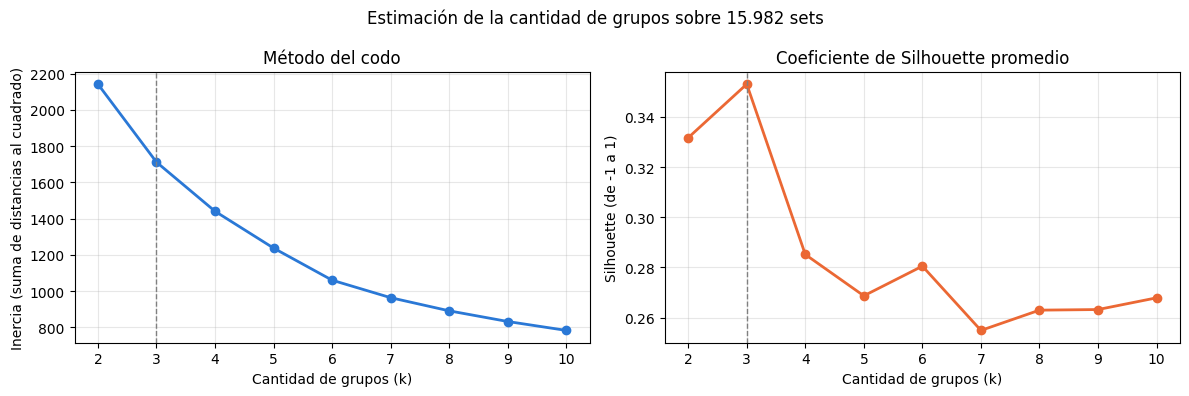

In [ ]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, silhouette_samples

generador = np.random.default_rng(0)
muestra   = generador.choice(len(X_escalado), 5000, replace=False)

rango_k, inercias, silhouettes = range(2, 11), [], []

for k in rango_k:
    modelo = KMeans(n_clusters=k, n_init=10, random_state=42).fit(X_escalado)
    inercias.append(modelo.inertia_)
    silhouettes.append(silhouette_score(X_escalado[muestra], modelo.labels_[muestra]))

display(pd.DataFrame({
    'k': list(rango_k),
    'inercia': np.round(inercias, 1),
    'silhouette': np.round(silhouettes, 3)
}))

fig, ax = plt.subplots(1, 2, figsize=(12, 4))

ax[0].plot(rango_k, inercias, '-o', color='#2a78d6', linewidth=2)
ax[0].axvline(3, linestyle='--', color='gray', linewidth=1)
ax[0].set_title('Método del codo')
ax[0].set_xlabel('Cantidad de grupos (k)')
ax[0].set_ylabel('Inercia (suma de distancias al cuadrado)')
ax[0].grid(alpha=0.3)

ax[1].plot(rango_k, silhouettes, '-o', color='#eb6834', linewidth=2)
ax[1].axvline(3, linestyle='--', color='gray', linewidth=1)
ax[1].set_title('Coeficiente de Silhouette promedio')
ax[1].set_xlabel('Cantidad de grupos (k)')
ax[1].set_ylabel('Silhouette (de -1 a 1)')
ax[1].grid(alpha=0.3)

fig.suptitle('Estimación de la cantidad de grupos sobre 15.982 sets')
plt.tight_layout()
plt.show()

Ambos criterios coinciden en **k = 3**. La inercia cae un 20% al pasar de 2 a 3 grupos y las caídas posteriores son menores y decrecientes, lo que ubica el codo en 3. El coeficiente de Silhouette alcanza su máximo en k = 3 con 0,353 y desciende para valores mayores.

El valor de 0,353 indica una estructura de agrupamiento moderada: los grupos existen pero presentan superposición en sus fronteras. Es un valor razonable para datos reales, y notoriamente inferior al que se obtiene en conjuntos de datos construidos con grupos bien separados.

In [ ]:
kmeans = KMeans(n_clusters=3, n_init=10, random_state=42)
ds_cluster['cluster'] = kmeans.fit_predict(X_escalado)

print('Cantidad de sets por grupo:')
display(ds_cluster['cluster'].value_counts().sort_index())

Cantidad de sets por grupo:


,count
cluster,
0,7600
1,7618
2,764


## Evaluación de la calidad de los grupos: análisis de Silhouette

El gráfico siguiente muestra el coeficiente de Silhouette de cada set, ordenado de
menor a mayor dentro de cada grupo. Permite evaluar no solo el promedio general
sino la calidad de cada grupo por separado y la presencia de observaciones mal
asignadas (valores negativos).

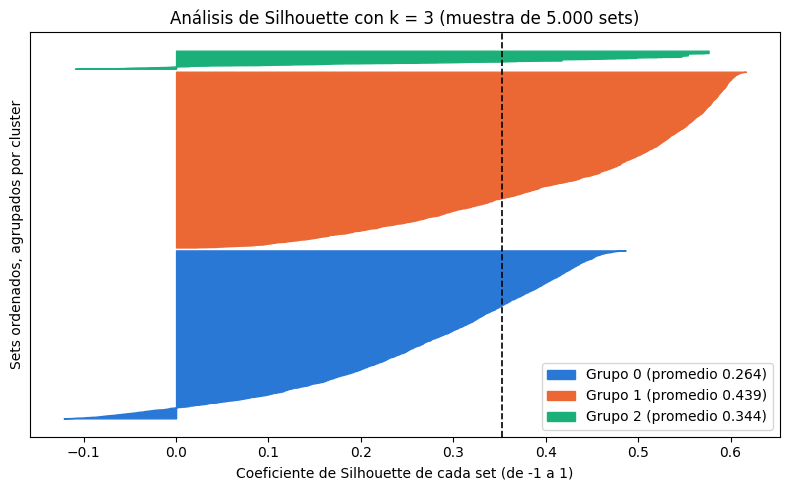

Grupo 0: Silhouette promedio = 0.264
Grupo 1: Silhouette promedio = 0.439
Grupo 2: Silhouette promedio = 0.344


In [ ]:
valores_silhouette = silhouette_samples(X_escalado[muestra], ds_cluster['cluster'].values[muestra])
etiquetas_muestra  = ds_cluster['cluster'].values[muestra]
colores_cluster    = ['#2a78d6', '#eb6834', '#1baf7a']

fig, ax = plt.subplots(figsize=(8, 5))
posicion = 10

for c in range(3):
    valores_c = np.sort(valores_silhouette[etiquetas_muestra == c])
    ax.fill_betweenx(np.arange(posicion, posicion + len(valores_c)), 0, valores_c,
                     color=colores_cluster[c], label=f'Grupo {c} (promedio {valores_c.mean():.3f})')
    posicion += len(valores_c) + 40

ax.axvline(valores_silhouette.mean(), linestyle='--', color='black', linewidth=1.2)
ax.set_title('Análisis de Silhouette con k = 3 (muestra de 5.000 sets)')
ax.set_xlabel('Coeficiente de Silhouette de cada set (de -1 a 1)')
ax.set_ylabel('Sets ordenados, agrupados por cluster')
ax.set_yticks([])
ax.legend(loc='lower right')
plt.tight_layout()
plt.show()

for c in range(3):
    print(f'Grupo {c}: Silhouette promedio = {valores_silhouette[etiquetas_muestra == c].mean():.3f}')

## Visualización de los grupos

Las cinco variables no pueden representarse simultáneamente en dos dimensiones.
Se aplica Análisis de Componentes Principales (PCA) para proyectarlas sobre dos
ejes que conservan la mayor parte de la variabilidad, con el único fin de
visualizar el resultado. El agrupamiento se realizó sobre las cinco variables
originales, no sobre las componentes.

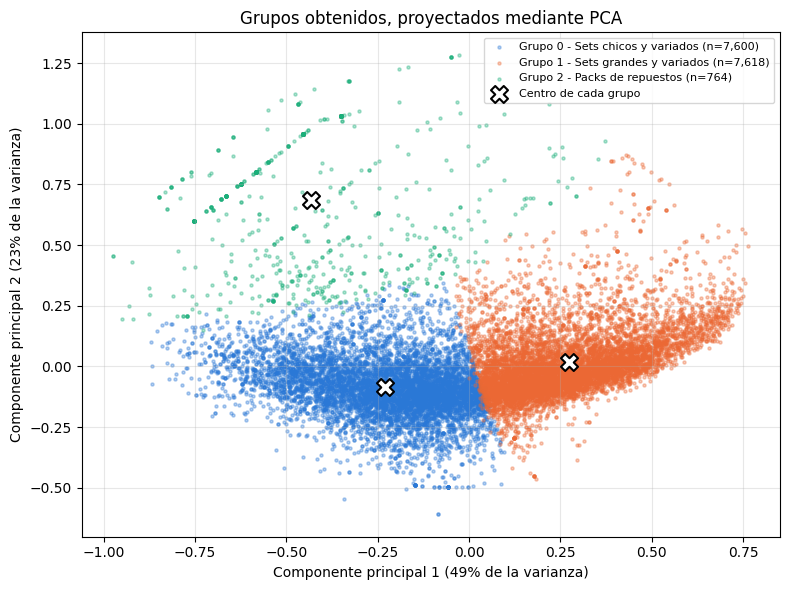

In [ ]:
from sklearn.decomposition import PCA

pca    = PCA(n_components=2)
coords = pca.fit_transform(X_escalado)
centros = pca.transform(kmeans.cluster_centers_)

nombres = {0: 'Sets chicos y variados', 1: 'Sets grandes y variados', 2: 'Packs de repuestos'}

fig, ax = plt.subplots(figsize=(8, 6))

for c in range(3):
    seleccion = ds_cluster['cluster'].values == c
    ax.scatter(coords[seleccion, 0], coords[seleccion, 1], s=5, alpha=0.35,
               color=colores_cluster[c],
               label=f'Grupo {c} - {nombres[c]} (n={seleccion.sum():,})')

ax.scatter(centros[:, 0], centros[:, 1], marker='X', s=150,
           c='white', edgecolors='black', linewidths=1.5, zorder=5,
           label='Centro de cada grupo')

ax.set_title('Grupos obtenidos, proyectados mediante PCA')
ax.set_xlabel(f'Componente principal 1 ({pca.explained_variance_ratio_[0]*100:.0f}% de la varianza)')
ax.set_ylabel(f'Componente principal 2 ({pca.explained_variance_ratio_[1]*100:.0f}% de la varianza)')
ax.legend(fontsize=8)
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

Las dos primeras componentes conservan el 72% de la variabilidad total, por lo que la proyección es representativa.

El grupo 2 aparece claramente separado del resto. En cambio, la frontera entre los grupos 0 y 1 es una línea recta, lo cual es característico de K-Means cuando se aplica sobre una distribución continua: el algoritmo divide el espacio en regiones delimitadas por rectas, independientemente de que exista o no una separación real en los datos. Esto indica que los grupos 0 y 1 no corresponden a dos poblaciones diferenciadas sino a los extremos de un mismo gradiente, y es coherente con el coeficiente de Silhouette moderado obtenido.

## Caracterización de los grupos

Se analizan las medianas de cada variable en unidades originales, junto con los
temas más frecuentes de cada grupo, para determinar en función de qué
características se formaron.

In [ ]:
resumen_clusters = ds_cluster.groupby('cluster').agg(
    sets          = ('num_piezas', 'size'),
    piezas        = ('num_piezas', 'median'),
    tipos_pieza   = ('piezas_unicas', 'median'),
    repeticion    = ('ratio_repeticion', 'median'),
    colores       = ('n_colores', 'median'),
    col_por_tipo  = ('colores_por_tipo', 'median'),
    cat_por_tipo  = ('cats_por_tipo', 'median'),
    transparentes = ('pct_transparentes', 'median'),
    anio          = ('year', 'median'),
).round(2)

display(resumen_clusters)

ds_cluster_tema = ds_cluster.merge(
    ds_themes_trabajo[['id', 'name']].rename(columns={'id': 'theme_id', 'name': 'tema'}),
    on='theme_id', how='left'
)

for c in range(3):
    temas = ds_cluster_tema[ds_cluster_tema['cluster'] == c]['tema'].value_counts().head(5)
    print(f'\nGrupo {c} - temas más frecuentes:')
    print(temas.to_string())

         sets  piezas  tipos_pieza  repeticion  colores  col_por_tipo  \
cluster                                                                 
0        7600    37.0         19.0        1.90      7.0          0.38   
1        7618   311.0         82.0        4.07     15.0          0.17   
2         764    45.5          2.0       20.00      2.0          1.00   

         cat_por_tipo  transparentes    anio  
cluster                                       
0                0.44           0.03  2011.0  
1                0.25           0.03  2016.0  
2                1.00           0.00  2003.0  


Grupo 0 - temas más frecuentes:
tema
Star Wars       355
Friends         344
Bionicle        244
Classic Town    238
Town            234

Grupo 1 - temas más frecuentes:
tema
Star Wars         524
Technic           434
Friends           316
Ninjago           234
Creator 3-in-1    218

Grupo 2 - temas más frecuentes:
tema
Technic         177
Bulk Bricks      88
Supplemental     60
Basic Set        57
DOTS             53


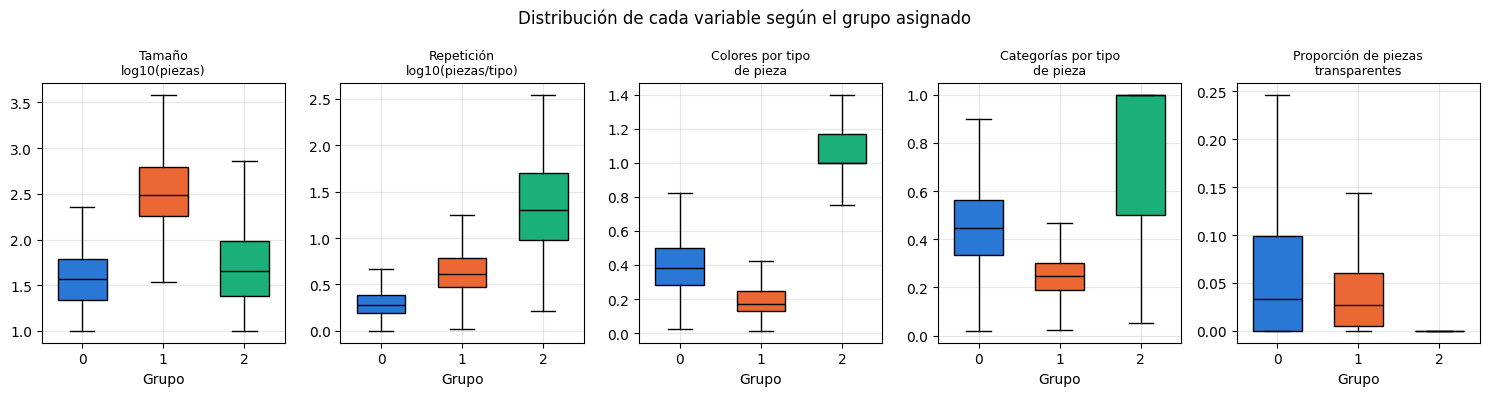

In [ ]:
etiquetas_variables = {
    'log_piezas'       : 'Tamaño\nlog10(piezas)',
    'log_ratio'        : 'Repetición\nlog10(piezas/tipo)',
    'colores_por_tipo' : 'Colores por tipo\nde pieza',
    'cats_por_tipo'    : 'Categorías por tipo\nde pieza',
    'pct_transparentes': 'Proporción de piezas\ntransparentes',
}

fig, axs = plt.subplots(1, 5, figsize=(15, 4))

for ax, variable in zip(axs, variables_cluster):
    datos = [ds_cluster.loc[ds_cluster['cluster'] == c, variable] for c in range(3)]
    bp = ax.boxplot(datos, patch_artist=True, showfliers=False, widths=0.6,
                    medianprops=dict(color='black'))
    for caja, color in zip(bp['boxes'], colores_cluster):
        caja.set_facecolor(color)
    ax.set_title(etiquetas_variables[variable], fontsize=9)
    ax.set_xlabel('Grupo')
    ax.set_xticklabels(['0', '1', '2'])
    ax.grid(alpha=0.3)

fig.suptitle('Distribución de cada variable según el grupo asignado')
plt.tight_layout()
plt.show()

## Conclusiones

El agrupamiento identificó tres grupos de sets:

**Grupo 2 - Packs de repuestos (764 sets).** Mediana de 45 piezas de solo 2 tipos distintos, con cada tipo repetido 20 veces, y 2 colores. Los temas más frecuentes son Technic, Bulk Bricks, Supplemental, Basic Set y DOTS. No se trata de modelos para armar sino de conjuntos de piezas sueltas. Es el grupo más pequeño y el único claramente separado del resto en la proyección.

**Grupo 1 - Sets grandes y variados (7.618 sets).** Mediana de 319 piezas, 82 tipos distintos y 15 colores. Predominan Star Wars, Technic, Friends, Ninjago y Creator 3-in-1.

**Grupo 0 - Sets chicos y variados (7.600 sets).** Mediana de 37 piezas pero 19 tipos distintos: prácticamente no repiten piezas. Entre sus temas más frecuentes están Star Wars, Friends, Bionicle, Classic Town y Town.

El hallazgo principal es que **la variable que estructura el agrupamiento no es el tamaño sino el grado de repetición de piezas**. El grupo 2 repite cada tipo de pieza unas 20 veces, el grupo 1 unas 4 y el grupo 0 menos de 2. El tamaño diferencia al grupo 1 del 0, pero no explica la separación del grupo 2, que tiene un tamaño mediano comparable al del grupo 0.

Este resultado es consecuencia directa de la decisión de reemplazar las variables de conteo correlacionadas por variables relativas. Con las variables originales, el agrupamiento habría reproducido una partición por tamaño.

La validación externa del grupo 2 refuerza el resultado: los temas que lo componen (Bulk Bricks, Supplemental) corresponden efectivamente a conjuntos de piezas sueltas según la clasificación de Rebrickable, categoría que el algoritmo identificó sin recibir esa información.

**Limitaciones.** El coeficiente de Silhouette de 0,353 indica superposición entre grupos, particularmente entre el 0 y el 1 (Silhouette 0,264 y 0,439 respectivamente; el grupo 2 alcanza 0,344). La frontera recta entre ambos en la proyección PCA sugiere que responden a un gradiente continuo más que a dos poblaciones diferenciadas. K-Means, al asumir grupos de forma esférica y tamaño similar, no es el método más adecuado para una estructura de ese tipo. Como trabajo futuro podría evaluarse un método de agrupamiento basado en densidad, que no impone esa restricción.